# 2.5.1 — Results: Gini by snapshot day, severity confusion matrices and decile tables

Input: the best model's prediction for every train / val / test row of each study, in `PREDICTIONS_DIR`
(set in `config.py`; git-ignored because the files contain claim numbers).

- **Day** = days after the claim opened. Each day scores the coverages still open and event-free on that day.
- **Gini** = 2·AUC − 1. For severity it is the support-weighted average of the 4 cumulative "band ≥ k" Ginis.
- **QWK** = quadratic-weighted kappa between the predicted band (argmax) and the true band.
- `severity_gini` was selected on Gini and `severity_qwk` on QWK (validation only).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, cohen_kappa_score, confusion_matrix

sys.path.insert(0, '../..')   # repo root, so config.py can be imported
from config import PREDICTIONS_DIR

STUDIES = ['attorney', 'litigation', 'severity_gini', 'severity_qwk']
SPLITS = {'train': 'train', 'val': 'val', 'holdout': 'test'}
SPLIT_COLORS = {'train': '#1f77b4', 'val': '#ff7f0e', 'holdout': '#2ca02c'}
BANDS = ['$0-2.5K', '$2.5-10K', '$10-25K', '$25-100K', '$100K+']
os.makedirs('figures', exist_ok=True)

preds = {s: pd.read_parquet(PREDICTIONS_DIR / f'{s}_predictions.parquet') for s in STUDIES}


def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1


def probs(d):
    return d[[f'pred_{k}' for k in range(5)]].to_numpy()


def ordinal_gini(y, P):
    g, w = [], []
    for k in range(1, 5):
        yk = (y >= k).astype(int); n_pos = yk.sum()
        if 0 < n_pos < len(yk):
            g.append(gini(yk, P[:, k:].sum(1))); w.append(min(n_pos, len(yk) - n_pos))
    return np.average(g, weights=w)


def by_day(df, split, metric):
    out = {}
    for day, d in df[df.split == split].groupby('snapshot_day'):
        if metric == 'gini' and 'pred' in d:
            out[day] = gini(d.label, d.pred)
        elif metric == 'gini':
            out[day] = ordinal_gini(d.label.to_numpy(), probs(d))
        else:
            out[day] = cohen_kappa_score(d.label, probs(d).argmax(1), weights='quadratic')
    return pd.Series(out)


def plot_days(ax, v, days, **kw):
    # days are evenly spaced on the x-axis (one slot per day on the grid)
    ax.plot([days.index(d) for d in v.index], v.values, marker='o', **kw)


def day_axis(ax, days):
    ax.set_xticks(range(len(days)), days); ax.grid(alpha=.3); ax.set_xlabel('snapshot day (days after claim open)')

## 1. Attorney and Litigation: Gini by snapshot day (train / val / test)

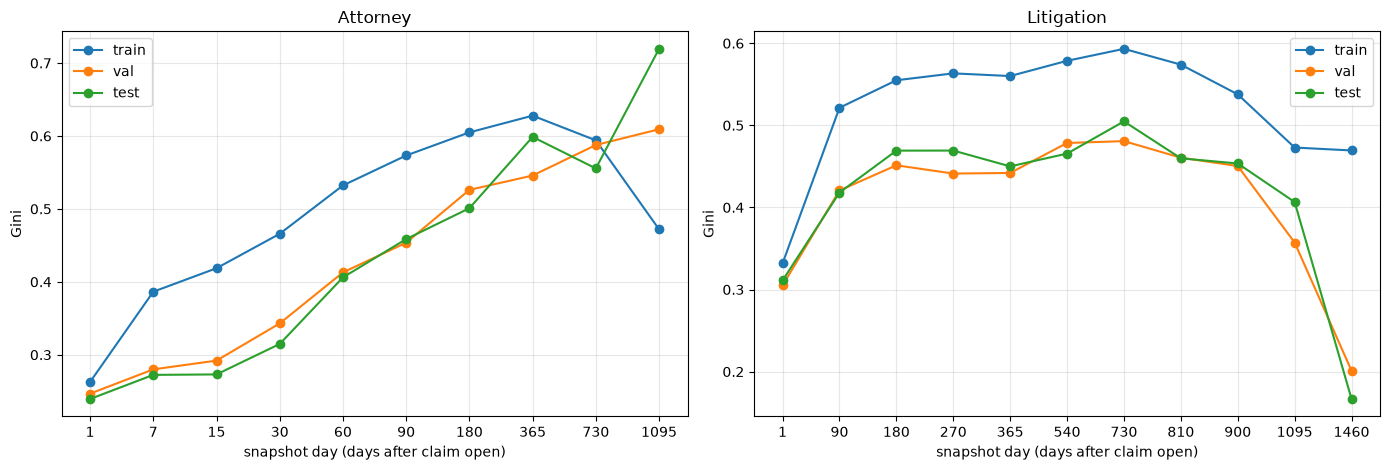

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, s in zip(axes, ['attorney', 'litigation']):
    days = [int(d) for d in sorted(preds[s].snapshot_day.unique())]
    for split, name in SPLITS.items():
        plot_days(ax, by_day(preds[s], split, 'gini'), days, color=SPLIT_COLORS[split], label=name)
    day_axis(ax, days)
    ax.set(ylabel='Gini', title=s.capitalize()); ax.legend()
plt.tight_layout(); plt.savefig('figures/gini_by_day_attorney_litigation.png', dpi=130); plt.show()

## 2. Severity: Gini and QWK by snapshot day, one panel per split

Four lines per panel: the Gini-selected and the QWK-selected model, each scored by Gini and by QWK.

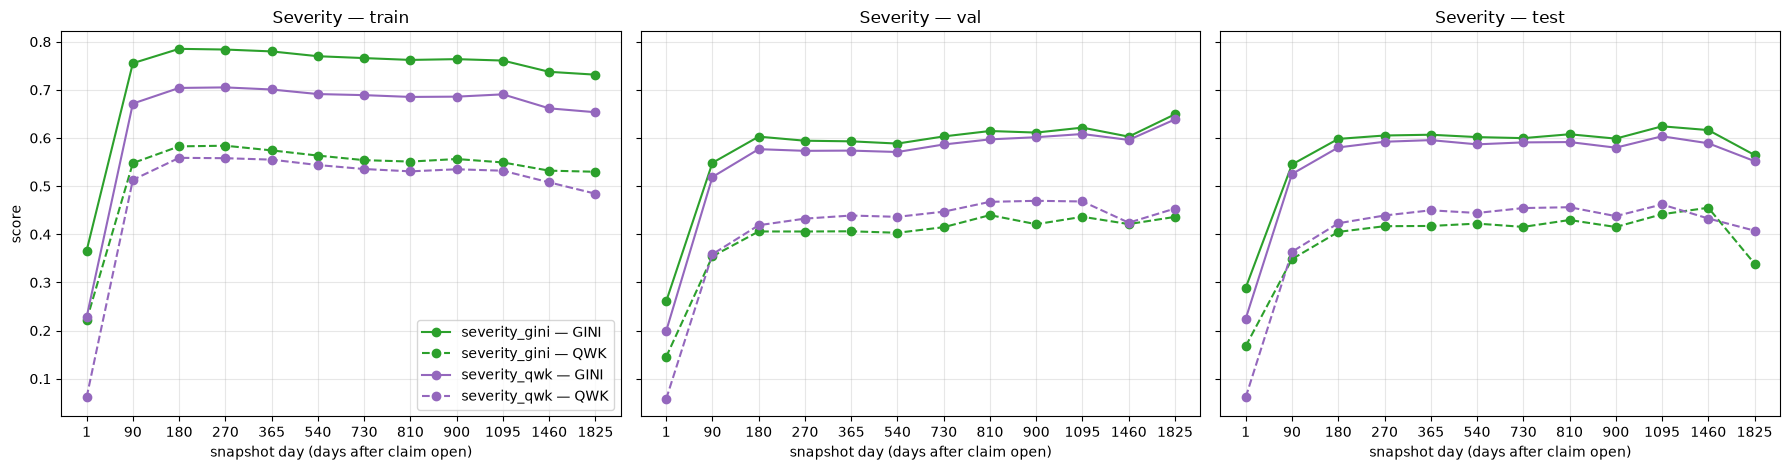

In [3]:
LINES = [('severity_gini', 'gini', '#2ca02c', '-'), ('severity_gini', 'qwk', '#2ca02c', '--'),
         ('severity_qwk', 'gini', '#9467bd', '-'), ('severity_qwk', 'qwk', '#9467bd', '--')]
days = [int(d) for d in sorted(preds['severity_gini'].snapshot_day.unique())]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, (split, name) in zip(axes, SPLITS.items()):
    for s, metric, color, ls in LINES:
        plot_days(ax, by_day(preds[s], split, metric), days, color=color, ls=ls, label=f'{s} — {metric.upper()}')
    day_axis(ax, days); ax.set_title(f'Severity — {name}')
axes[0].set_ylabel('score'); axes[0].legend()
plt.tight_layout(); plt.savefig('figures/severity_by_day.png', dpi=130); plt.show()

## 3. Severity confusion matrices at selected cutoff days (test)

Each panel shows the test coverages scored on that snapshot day, one row of panels per severity model. Rows are
the true band and columns the predicted band. Each row is normalized to sum to 1.

On day 1, with only a few notes, almost every claim is predicted as one of the two lowest bands (for the
QWK-selected model, 83% of `$100K+` claims are predicted as `$0-2.5K`). By day 1,095 the expensive claims are
mostly recognized: 49% to 65% of `$25-100K` and `$100K+` claims land in their true band.

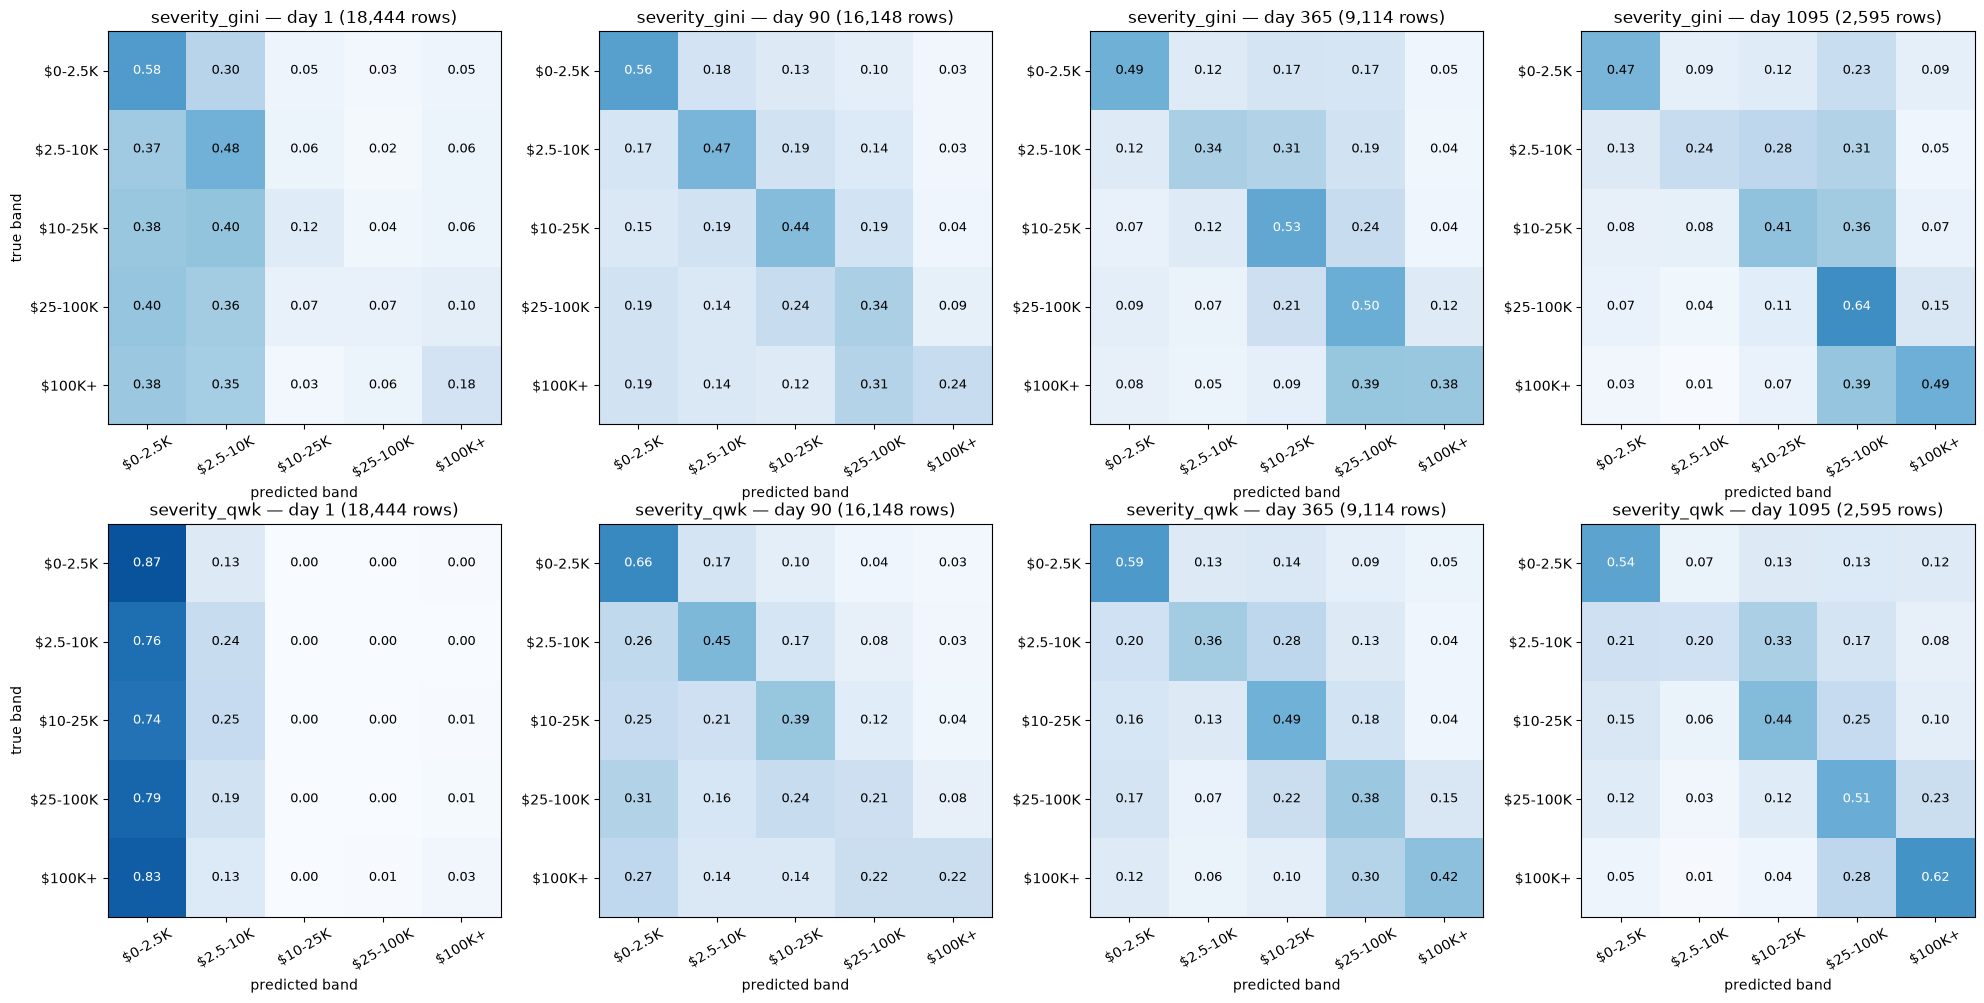

In [4]:
CUTOFF_DAYS = [1, 90, 365, 1095]
fig, axes = plt.subplots(2, len(CUTOFF_DAYS), figsize=(5 * len(CUTOFF_DAYS), 10))
for r, s in enumerate(['severity_gini', 'severity_qwk']):
    h = preds[s][preds[s].split == 'holdout']
    for c, day in enumerate(CUTOFF_DAYS):
        ax, d = axes[r, c], h[h.snapshot_day == day]
        cm = confusion_matrix(d.label, probs(d).argmax(1), labels=range(5), normalize='true')
        ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center',
                        color='white' if cm[i, j] > .5 else 'black', fontsize=9)
        ax.set_xticks(range(5), BANDS, rotation=30); ax.set_yticks(range(5), BANDS)
        ax.set_title(f'{s} — day {day} ({len(d):,} rows)')
        ax.set_xlabel('predicted band')
        if c == 0:
            ax.set_ylabel('true band')
plt.tight_layout(); plt.savefig('figures/severity_confusion_by_day.png', dpi=130); plt.show()

## 4. Decile tables by cutoff day: Attorney and Litigation

How the deciles are built:
- For the chosen cutoff day, that day's **validation** rows are sorted by predicted score (stable sort) and split
  into 10 groups with the same number of rows. D1 holds the highest scores.
- **Test** rows of the same day are placed into those validation score ranges. A row goes to the highest decile
  whose lowest validation score it reaches, so test decile sizes vary a little.
- Coverages counts the coverages in the decile on that day, which is one row each. Rates use each coverage's final
  outcome. The cumulative columns add up from D1 down.

Use the buttons and the slider to pick the model, the rows shown and the cutoff day. Every table is precomputed
into the output, so the slider works when the saved notebook is opened, without re-running it.

In [5]:
import html as _html, json, uuid
from IPython.display import HTML


def _cell(v, fmt, heat=None):
    txt = '–' if v is None or (isinstance(v, float) and np.isnan(v)) else fmt.format(v)
    style = '' if heat is None or txt == '–' else f' style="background:rgba(31,95,139,{min(1, heat) * 0.45:.3f})"'
    return f'<td{style}>{txt}</td>'


def table_html(df, fmts, heat_cols=()):
    # compact HTML table; heat_cols are shaded relative to their column maximum
    mx = {c: np.nanmax(df[c].to_numpy(float)) for c in heat_cols}
    head = ''.join(f'<th>{_html.escape(c)}</th>' for c in df.columns)
    body = ''
    for _, r in df.iterrows():
        body += '<tr>' + ''.join(_cell(r[c], fmts.get(c, '{}'), (r[c] / mx[c] if c in mx and mx[c] > 0 else None))
                               for c in df.columns) + '</tr>'
    return f'<table class="dt"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>'


def slider_view(views, models, splits, days_by_model, title):
    '''views: {(model, split, day): html}. Renders buttons + a day slider in plain HTML/JS (no kernel needed).
    The first view is also written as static HTML, so it shows even where scripts are blocked.'''
    uid = 'v' + uuid.uuid4().hex[:8]
    first = (models[0], splits[0][0], days_by_model[models[0]][0])
    data = json.dumps({f'{m}|{sp}|{d}': h for (m, sp, d), h in views.items()})
    btn = lambda grp, opts: ''.join(
        f'<button data-g="{grp}" data-v="{v}" class="{"on" if i == 0 else ""}">{l}</button>' for i, (v, l) in enumerate(opts))
    return HTML(f'''
<div id="{uid}" class="dtwrap">
<style>
#{uid} {{font-family:system-ui,sans-serif;font-size:13px}}
#{uid} .bar {{margin:4px 0}} #{uid} .bar b {{display:inline-block;width:90px}}
#{uid} button {{border:1px solid #9aa;background:#f4f6f8;padding:3px 10px;margin-right:4px;border-radius:5px;cursor:pointer}}
#{uid} button.on {{background:#1f5f8b;color:#fff;border-color:#1f5f8b}}
#{uid} input[type=range] {{width:420px;vertical-align:middle}}
#{uid} .out {{overflow-x:auto;max-width:100%}}
#{uid} .dt {{border-collapse:collapse;margin-top:6px}}
#{uid} .dt th,#{uid} .dt td {{border:1px solid #d5dde5;padding:4px 8px;text-align:right;white-space:nowrap}}
#{uid} .dt th {{background:#eef2f6}} #{uid} .dt td:first-child,#{uid} .dt th:first-child {{text-align:left}}
</style>
<div style="font-weight:600;margin-bottom:4px">{title}</div>
<div class="bar"><b>Model</b>{btn('m', [(m, m) for m in models])}</div>
<div class="bar"><b>Rows shown</b>{btn('s', splits)}</div>
<div class="bar"><b>Cutoff day</b><input type="range" min="0" step="1" value="0"> <span class="day"></span></div>
<div class="out">{views[first]}</div>
</div>
<script>
(function(){{
 const root=document.getElementById('{uid}'), V={data}, D={json.dumps({m: list(map(int, d)) for m, d in days_by_model.items()})};
 const st={{m:'{first[0]}', s:'{first[1]}', i:0}}, r=root.querySelector('input'), lab=root.querySelector('.day'), out=root.querySelector('.out');
 function draw(){{ const days=D[st.m]; if(st.i>=days.length) st.i=days.length-1; r.max=days.length-1; r.value=st.i;
   lab.textContent='day '+days[st.i]+'  ('+days.join(', ')+')'; out.innerHTML=V[st.m+'|'+st.s+'|'+days[st.i]]; }}
 root.querySelectorAll('button').forEach(b=>b.onclick=()=>{{
   root.querySelectorAll('button[data-g='+b.dataset.g+']').forEach(x=>x.classList.remove('on')); b.classList.add('on');
   if(b.dataset.g==='m'){{st.m=b.dataset.v;st.i=0;}} else st.s=b.dataset.v; draw(); }});
 r.oninput=()=>{{st.i=+r.value; draw();}}; draw();
}})();
</script>''')

BAND_NAMES = {4: '$100K+', 3: '$25K-$100K', 2: '$10K-$25K', 1: '$2.5K-$10K', 0: 'under $2.5K'}


def score_of(d):
    # binary: predicted probability; severity: expected band = sum_k k * P(band k)
    return d.pred.to_numpy() if 'pred' in d else probs(d) @ np.arange(5)


def assign_deciles(df, day, split):
    # returns (rows of the chosen split with a 'dec' column 0..9, validation score range per decile)
    d = df[df.snapshot_day == day].copy()
    d['score'] = score_of(d)
    v = d[d.split == 'val'].sort_values('score', ascending=False, kind='mergesort')
    groups = np.array_split(np.arange(len(v)), 10)
    ranges = [(v.score.iloc[g].min(), v.score.iloc[g].max()) for g in groups]
    if split == 'val':
        dec = np.empty(len(v), dtype=int)
        for q, g in enumerate(groups):
            dec[g] = q
        return v.assign(dec=dec), ranges
    t = d[d.split == 'holdout'].copy()
    dec = np.full(len(t), 9)
    for q in range(8, -1, -1):
        dec[t.score.to_numpy() >= ranges[q][0]] = q
    return t.assign(dec=dec), ranges


def binary_decile_table(study, day, split):
    t, ranges = assign_deciles(preds[study], day, split)
    g = t.groupby('dec')
    out = pd.DataFrame({
        'Decile': [f'D{q + 1}' for q in range(10)],
        'Score range': [f'{lo:.3f} – {hi:.3f}' for lo, hi in ranges],
        'Coverages': g.size().reindex(range(10), fill_value=0).to_numpy(),
        'Avg predicted': g.score.mean().reindex(range(10)).to_numpy(),
        f'Actual {study} rate': g.label.mean().reindex(range(10)).to_numpy(),
    })
    pos = g.label.sum().reindex(range(10), fill_value=0).to_numpy()
    out.insert(3, 'Cumulative % of coverages', out.Coverages.cumsum() / out.Coverages.sum())
    out[f'Cumulative % of {study} cases'] = pos.cumsum() / pos.sum()
    return out


def binary_view(study, split, day):
    tab = binary_decile_table(study, day, split)
    rate, cum = f'Actual {study} rate', f'Cumulative % of {study} cases'
    head = (f"<p>{study} model on {'test' if split == 'holdout' else 'validation'} rows, cutoff day {day}, "
            f"{tab.Coverages.sum():,} coverage rows</p>")
    return head + table_html(tab, {'Coverages': '{:,}', 'Cumulative % of coverages': '{:.1%}', 'Avg predicted': '{:.3f}',
                                   rate: '{:.1%}', cum: '{:.1%}'}, heat_cols=[rate])


SPLIT_OPTS = [('holdout', 'Test'), ('val', 'Validation')]
b_days = {m: sorted(preds[m].snapshot_day.unique()) for m in ['attorney', 'litigation']}
b_views = {(m, sp, int(d)): binary_view(m, sp, int(d)) for m in b_days for sp, _ in SPLIT_OPTS for d in b_days[m]}
slider_view(b_views, ['attorney', 'litigation'], SPLIT_OPTS, b_days, 'Decile table by cutoff day')

Decile,Score range,Coverages,Cumulative % of coverages,Avg predicted,Actual attorney rate,Cumulative % of attorney cases
D1,0.622 – 0.767,"1,848",10.4%,0.659,59.4%,15.3%
D2,0.581 – 0.621,"1,782",20.4%,0.600,50.4%,27.8%
D3,0.547 – 0.581,"1,843",30.8%,0.564,48.1%,40.1%
D4,0.519 – 0.547,"1,619",39.9%,0.533,42.6%,49.7%
D5,0.492 – 0.519,"1,751",49.8%,0.505,42.0%,59.9%
D6,0.464 – 0.492,"1,754",59.7%,0.478,38.7%,69.4%
D7,0.435 – 0.464,"1,777",69.7%,0.450,35.2%,78.1%
D8,0.406 – 0.435,"1,763",79.6%,0.421,34.3%,86.5%
D9,0.368 – 0.406,"1,817",89.8%,0.389,29.3%,93.9%
D10,0.234 – 0.368,"1,809",100.0%,0.336,24.3%,100.0%


## 5. Severity by cutoff day: decile table and Gini per band threshold

The deciles use the same method, ranked by the **expected band**: Σ k·P(band k), from 0 (all probability on band 0)
to 4 (all on band 4). D1 holds the highest expected band.
- **Predicted** columns average the model's probability for each band, so each row adds to 100%.
- **Actual** columns give the share of the decile's coverages that ended in each band, so each row adds to 100%.

Below the decile table is the Gini for that day and split at each band threshold, each scored by P(band ≥ k):
band 4 vs rest, bands 3–4 vs rest, bands 2–4 vs rest, and bands 1–4 vs band 0.

In [6]:
THRESHOLDS = [(4, 'Band 4 vs rest'), (3, 'Bands 3–4 vs rest'), (2, 'Bands 2–4 vs rest'), (1, 'Bands 1–4 vs band 0')]


def severity_decile_table(study, day, split):
    t, ranges = assign_deciles(preds[study], day, split)
    P = probs(t); rows = []
    for q in range(10):
        m = t.dec.to_numpy() == q
        r = {'Decile': f'D{q + 1}', 'Score range (expected band)': f'{ranges[q][0]:.2f} – {ranges[q][1]:.2f}',
             'Coverages': int(m.sum())}
        for b in [4, 3, 2, 1, 0]:
            r[f'P(band {b})'] = P[m, b].mean() if m.any() else np.nan
        for b in [4, 3, 2, 1, 0]:
            r[f'Actual band {b} ({BAND_NAMES[b]})'] = (t.label.to_numpy()[m] == b).mean() if m.any() else np.nan
        rows.append(r)
    out = pd.DataFrame(rows)
    out.insert(3, 'Cumulative % of coverages', out.Coverages.cumsum() / out.Coverages.sum())
    return out


def severity_gini_table(study, day, split):
    d = preds[study][(preds[study].snapshot_day == day) & (preds[study].split == split)]
    P, y = probs(d), d.label.to_numpy()
    rows = []
    for k, name in THRESHOLDS:
        yk = (y >= k).astype(int)
        rows.append({'Threshold': name, 'Positive rows': int(yk.sum()), 'Rows': len(yk),
                     'Gini': gini(yk, P[:, k:].sum(1)) if 0 < yk.sum() < len(yk) else np.nan})
    return pd.DataFrame(rows)


def severity_view(study, split, day):
    tab = severity_decile_table(study, day, split)
    pcols = [c for c in tab if c.startswith('P(')]; acols = [c for c in tab if c.startswith('Actual')]
    head = (f"<p>{study} model on {'test' if split == 'holdout' else 'validation'} rows, cutoff day {day}, "
            f"{tab.Coverages.sum():,} coverage rows</p>")
    dec = table_html(tab, {'Coverages': '{:,}', 'Cumulative % of coverages': '{:.1%}'} | {c: '{:.1%}' for c in pcols + acols},
                     heat_cols=acols)
    g = table_html(severity_gini_table(study, day, split), {'Positive rows': '{:,}', 'Rows': '{:,}', 'Gini': '{:.3f}'})
    return head + dec + '<p style="font-weight:600;margin-top:10px">Gini per band threshold</p>' + g


s_days = {m: sorted(preds[m].snapshot_day.unique()) for m in ['severity_gini', 'severity_qwk']}
s_views = {(m, sp, int(d)): severity_view(m, sp, int(d)) for m in s_days for sp, _ in SPLIT_OPTS for d in s_days[m]}
slider_view(s_views, ['severity_gini', 'severity_qwk'], SPLIT_OPTS, s_days, 'Severity decile table and Gini per band threshold by cutoff day')

Decile,Score range (expected band),Coverages,Cumulative % of coverages,P(band 4),P(band 3),P(band 2),P(band 1),P(band 0),Actual band 4 ($100K+),Actual band 3 ($25K-$100K),Actual band 2 ($10K-$25K),Actual band 1 ($2.5K-$10K),Actual band 0 (under $2.5K)
D1,1.93 – 3.79,"1,794",9.7%,27.9%,20.6%,14.2%,17.7%,19.6%,8.9%,14.0%,12.8%,14.5%,49.8%
D2,1.77 – 1.93,"1,803",19.5%,18.1%,18.4%,16.6%,23.2%,23.7%,5.9%,11.8%,10.1%,16.7%,55.5%
D3,1.66 – 1.77,"1,770",29.1%,15.1%,17.2%,17.1%,24.9%,25.6%,4.3%,9.7%,11.4%,15.8%,58.9%
D4,1.58 – 1.66,"1,884",39.3%,12.6%,16.2%,18.3%,26.3%,26.7%,3.0%,9.0%,12.4%,15.1%,60.5%
D5,1.50 – 1.58,"1,834",49.3%,10.6%,15.0%,19.4%,27.4%,27.6%,2.8%,7.6%,14.0%,16.7%,58.8%
D6,1.42 – 1.50,"1,841",59.2%,8.6%,13.9%,20.5%,28.9%,28.1%,2.5%,8.0%,12.5%,18.8%,58.2%
D7,1.34 – 1.42,"1,828",69.1%,6.9%,12.6%,21.2%,30.4%,28.8%,1.8%,6.3%,12.3%,18.6%,61.0%
D8,1.24 – 1.34,"1,708",78.4%,5.8%,11.3%,20.7%,31.4%,30.9%,1.8%,4.7%,14.2%,16.6%,62.7%
D9,1.00 – 1.24,"1,926",88.9%,4.5%,10.1%,18.7%,28.7%,37.9%,1.2%,4.3%,9.4%,14.6%,70.5%
D10,0.16 – 1.00,"2,056",100.0%,2.1%,6.6%,11.8%,18.2%,61.3%,1.2%,2.2%,5.7%,6.2%,84.7%
